# Weather Data Analysis





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('/content/weather_data.csv')
print(df)

      Formatted Date          Time        Summary Precip Type  \
0           4/1/2006  00:00:00.000  Partly Cloudy        rain   
1           4/1/2006  01:00:00.000  Partly Cloudy        rain   
2           4/1/2006  02:00:00.000  Mostly Cloudy        rain   
3           4/1/2006  03:00:00.000  Partly Cloudy        rain   
4           4/1/2006  04:00:00.000  Mostly Cloudy        rain   
...              ...           ...            ...         ...   
96448       9/9/2016  19:00:00.000  Partly Cloudy        rain   
96449       9/9/2016  20:00:00.000  Partly Cloudy        rain   
96450       9/9/2016  21:00:00.000  Partly Cloudy        rain   
96451       9/9/2016  22:00:00.000  Partly Cloudy        rain   
96452       9/9/2016  23:00:00.000  Partly Cloudy        rain   

       Temperature (C)  Apparent Temperature (C)  Wind Speed (km/h)  \
0             9.472222                  7.388889            14.1197   
1             9.355556                  7.227778            14.2646   
2     

In [7]:
df.shape

(96453, 14)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Time                      96453 non-null  object 
 2   Summary                   96453 non-null  object 
 3   Precip Type               95936 non-null  object 
 4   Temperature (C)           96453 non-null  float64
 5   Apparent Temperature (C)  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Pressure (millibars)      96453 non-null  float64
 10  Humidity                  96453 non-null  float64
 11  Month                     96453 non-null  int64  
 12  Day                       96453 non-null  int64  
 13  Year                      96453 non-null  int64  
dtypes: flo

In [10]:
df.describe()

,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
std,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000


# Checking Missing Values

In [12]:
df.isnull().sum()

,0
Formatted Date,0
Time,0
Summary,0
Precip Type,517
Temperature (C),0
Apparent Temperature (C),0
Wind Speed (km/h),0
Wind Bearing (degrees),0
Visibility (km),0
Pressure (millibars),0


In [13]:
df['Precip Type'] = df['Precip Type'].fillna('No Precip')
df.isnull().sum()

,0
Formatted Date,0
Time,0
Summary,0
Precip Type,0
Temperature (C),0
Apparent Temperature (C),0
Wind Speed (km/h),0
Wind Bearing (degrees),0
Visibility (km),0
Pressure (millibars),0


Missing Values Handling

In this dataset, only one column had missing values.
Precip Type had 517 missing values out of 96453 rows.
All other columns like Temperature, Humidity, Wind Speed, Pressure, Visibility had 0 missing values.

Reason: When there was no rain or snow, the Precip Type was left empty in the original data.

Solution: I filled these 517 missing values with 'No Precip' using fillna() method, because it means there was no precipitation on that day. I did not delete these rows because the rest of the data (Temperature, Humidity etc.) was complete and useful.

After filling, I checked again with isnull().sum() and all columns showed 0 missing values.

# Checking Duplicate Values

In [15]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 24


In [16]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape)

Rows after removing duplicates: (96429, 14)


Duplicates Handling

I checked for duplicate rows using duplicated().sum().
Result was 24 duplicate rows. These are repeated entries of same hour, which can give wrong results in analysis.

Solution: I removed these 24 duplicate rows using drop_duplicates() method.
After removing, total rows changed from 96453 to 96429.
Now the dataset has only unique records.

# Outliers Detection
  

#   Checking Outliers in Temperature



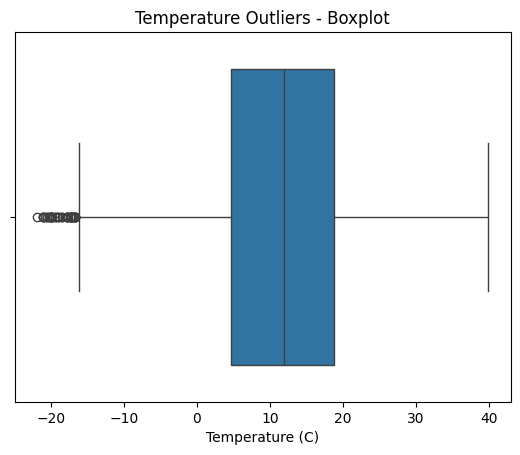

In [17]:
sns.boxplot(x=df['Temperature (C)'])
plt.title("Temperature Outliers - Boxplot")
plt.show()

#   Checking Outliers IN All Numeric Columns

In the previous step, I only checked outliers for Temperature. Now I checked outliers for all numeric columns to understand the complete data.

I used IQR method to count outliers. In this method, any value which is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is considered an outlier.

In [18]:
 for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    print(col, "-> Outliers:", outliers)

Temperature (C) -> Outliers: 44
Apparent Temperature (C) -> Outliers: 22
Wind Speed (km/h) -> Outliers: 3020
Wind Bearing (degrees) -> Outliers: 0
Visibility (km) -> Outliers: 0
Pressure (millibars) -> Outliers: 4400
Humidity -> Outliers: 46
Month -> Outliers: 0
Day -> Outliers: 0
Year -> Outliers: 0


### Result and Handling of Outliers

From the above result, we can see outliers in different columns:

- Temperature (C) -> Outliers: 44
- Apparent Temperature (C) -> Outliers: 22
- Wind Speed (km/h) -> Outliers: 3020
- Wind Bearing (degrees) -> Outliers: 0
- Visibility (km) -> Outliers: 0
- Pressure (millibars) -> Outliers: 4400
- Humidity -> Outliers: 46
- Month, Day, Year -> Outliers: 0

Wind Speed and Pressure have more outliers because these values change very quickly in real weather. For example, wind can be very slow on a normal day and very fast during a storm.

These outliers are real weather conditions, not wrong entries. If we delete them, we will lose important information about extreme weather. So, I decided to keep all outliers and did not remove them.

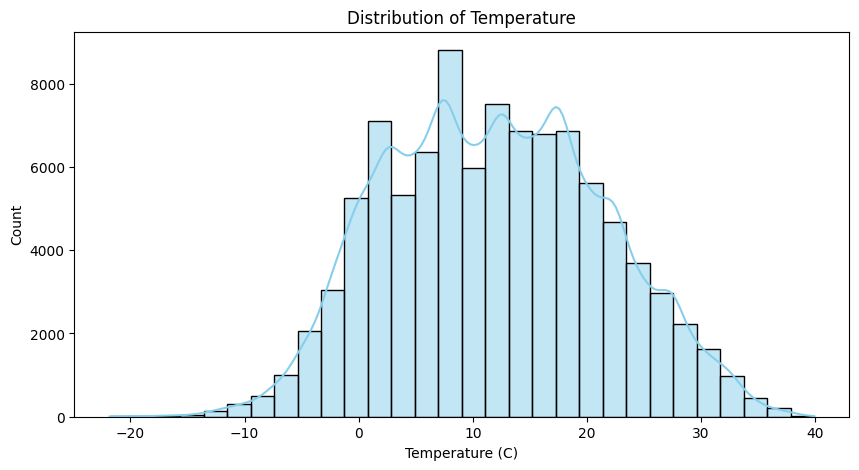

In [19]:
plt.figure(figsize=(10,5))
sns.histplot(df['Temperature (C)'], kde=True, bins=30, color='skyblue')
plt.title("Distribution of Temperature")
plt.xlabel("Temperature (C)")
plt.ylabel("Count")
plt.show()

From this graph, we can see that the Temperature is normally distributed. Most of the values are between 0°C to 22°C.

The highest peak is around 8°C to 10°C, which means most of the days had temperature in this range. Very cold days below -10°C and very hot days above 30°C are very few.

#  Count of Precipitation Type



/tmp/ipykernel_794/341510007.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Precip Type'], palette='pastel')


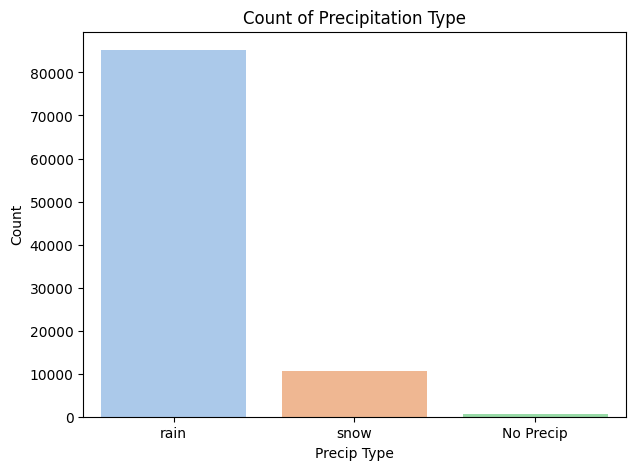

In [20]:
plt.figure(figsize=(7,5))
sns.countplot(x=df['Precip Type'], palette='pastel')
plt.title("Count of Precipitation Type")
plt.xlabel("Precip Type")
plt.ylabel("Count")
plt.show()

From this graph, we can clearly see that rain is the most common precipitation type. Rain occurred around 85,000 times, while snow occurred only around 11,000 times.

"No Precip" is very less, almost negligible. This means in most of the records, there was some kind of precipitation, and rain is much more common than snow.

#  Temperature vs Apparent Temperature



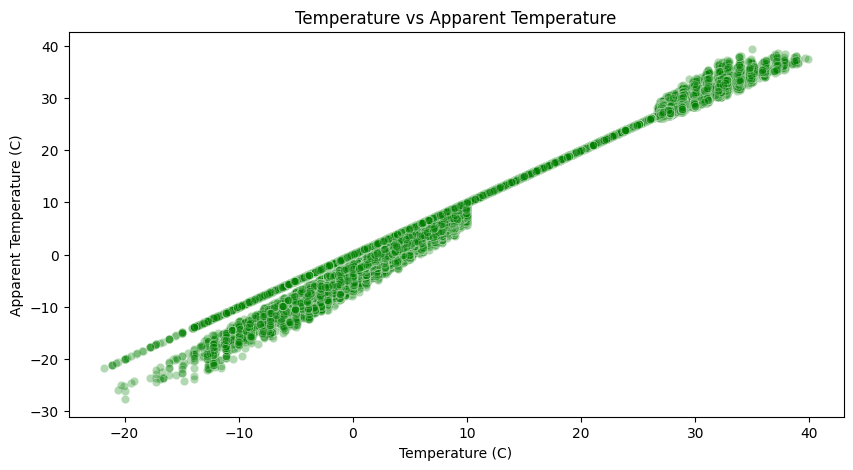

In [21]:
plt.figure(figsize=(10,5))
sns.scatterplot(x=df['Temperature (C)'], y=df['Apparent Temperature (C)'], alpha=0.3, color='green')
plt.title("Temperature vs Apparent Temperature")
plt.xlabel("Temperature (C)")
plt.ylabel("Apparent Temperature (C)")
plt.show()

From this scatter plot, we can see a very strong positive relationship between Temperature and Apparent Temperature. When Temperature increases, Apparent Temperature also increases.

Most of the points are on a straight line, which means Apparent Temperature is almost same as Actual Temperature.

Only in very cold weather (below 0°C), Apparent Temperature is slightly less than Actual Temperature. This is because of wind chill effect - when it is cold and windy, it feels more cold than the actual temperature.

#  Correlation Heatmap

This heatmap shows the correlation between all numeric columns. Value near 1  

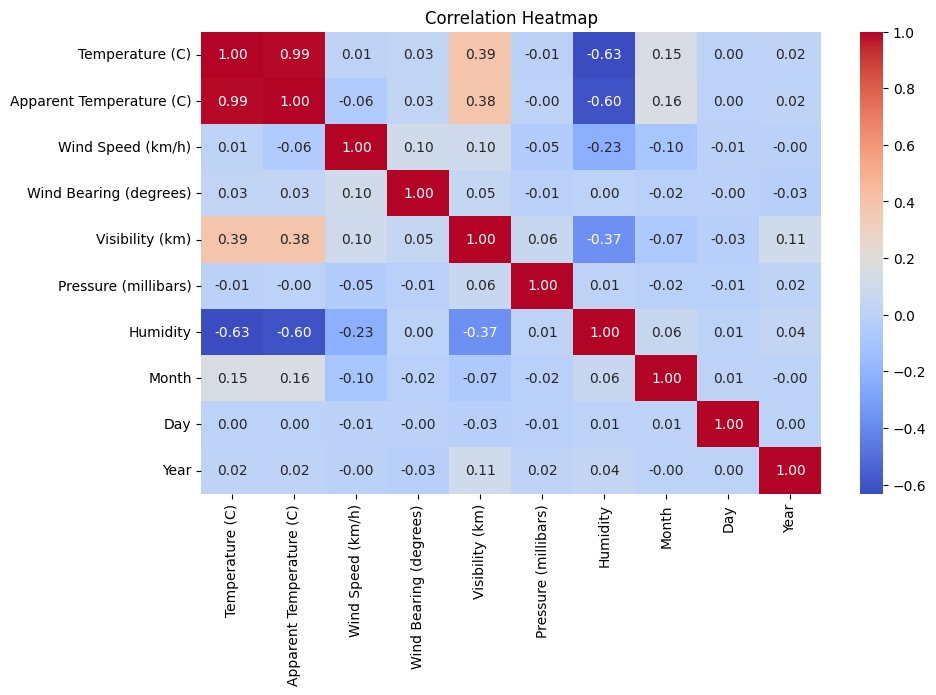

In [22]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

From the heatmap, we can see some very clear relationships:

1. Temperature and Apparent Temperature have correlation 0.99, which is almost perfect. This means both increase and decrease together.

2. Temperature and Humidity have correlation -0.63, which is a strong negative relation. This means when Temperature increases, Humidity decreases. Hot days are less humid.

3. Temperature and Visibility have correlation 0.39, which means on warm days visibility is better.

4. Most other columns like Wind Bearing, Pressure, Month, Day, Year have correlation near 0 with other columns, which means they have no strong relation.

So, the most important finding is that Temperature, Apparent Temperature and Humidity are strongly connected with each other.

# Analysis Questions


Q1. How does temperature affect apparent temperature?

Q2. Which precipitation type is most common in the dataset: Rain or Snow?

Q3. What is the relationship between temperature and humidity?

Q4. Which numerical columns contain the highest number of outliers?

Q5. How does visibility change with increasing temperature?

Correlation: 0.9926254234650596


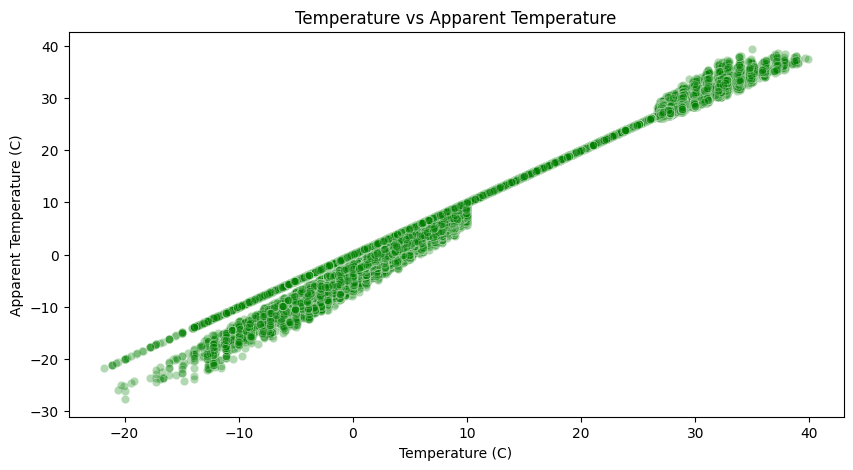

In [23]:
# Q1. How does temperature affect apparent temperature?
 # Calculate correlation
correlation = df['Temperature (C)'].corr(df['Apparent Temperature (C)'])

print("Correlation:", correlation)

# Scatter Plot
plt.figure(figsize=(10,5))
sns.scatterplot(
    x=df['Temperature (C)'],
    y=df['Apparent Temperature (C)'],
    color='green',
    alpha=0.3
)

plt.title("Temperature vs Apparent Temperature")
plt.xlabel("Temperature (C)")
plt.ylabel("Apparent Temperature (C)")
plt.show()


 #  Conclusion

The scatter plot shows that most points follow a straight-line pattern. This indicates that actual temperature and apparent temperature are almost the same. Therefore, temperature has a strong positive effect on apparent temperature.

Precip Type
rain         85200
snow         10712
No Precip      517
Name: count, dtype: int64


/tmp/ipykernel_794/1038083896.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Precip Type'], palette='pastel')


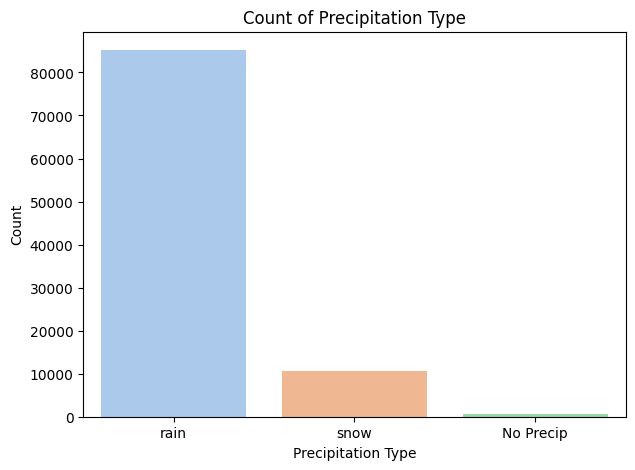

In [24]:
# Q2. Which precipitation type is most common in the dataset: Rain or Snow?


# Count Precipitation Types
print(df['Precip Type'].value_counts())

# Bar Chart
plt.figure(figsize=(7,5))
sns.countplot(x=df['Precip Type'], palette='pastel')

plt.title("Count of Precipitation Type")
plt.xlabel("Precipitation Type")
plt.ylabel("Count")
plt.show()


# Conclusion
The analysis shows that Rain is the dominant precipitation type in the dataset. Snow occurs less frequently, and records with no precipitation are very few. Therefore, rain is the most common weather condition in this dataset.

**Output Results**

Precipitation Type Count

    Rain        	85,200

    Snow	        10,712

    No Precip	    517

Correlation: -0.6323310338495954


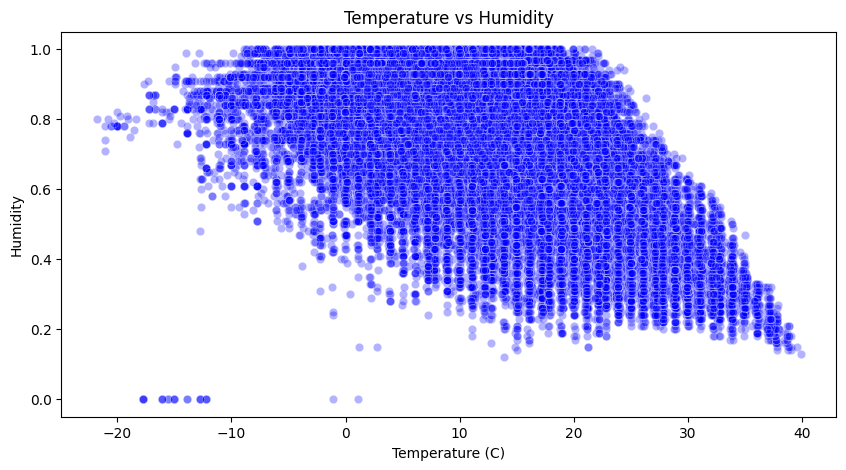

In [25]:
# Q3. What is the relationship between Temperature and Humidity?


# Calculate Correlation
correlation = df['Temperature (C)'].corr(df['Humidity'])

print("Correlation:", correlation)

# Scatter Plot
plt.figure(figsize=(10,5))
sns.scatterplot(
    x=df['Temperature (C)'],
    y=df['Humidity'],
    color='blue',
    alpha=0.3
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (C)")
plt.ylabel("Humidity")
plt.show()


# Conclusion

The analysis shows that Temperature and Humidity have a strong negative correlation. Higher temperatures are generally associated with lower humidity in this weather dataset.

Temperature (C) -> Outliers: 44
Apparent Temperature (C) -> Outliers: 22
Wind Speed (km/h) -> Outliers: 3020
Wind Bearing (degrees) -> Outliers: 0
Visibility (km) -> Outliers: 0
Pressure (millibars) -> Outliers: 4400
Humidity -> Outliers: 46
Month -> Outliers: 0
Day -> Outliers: 0
Year -> Outliers: 0


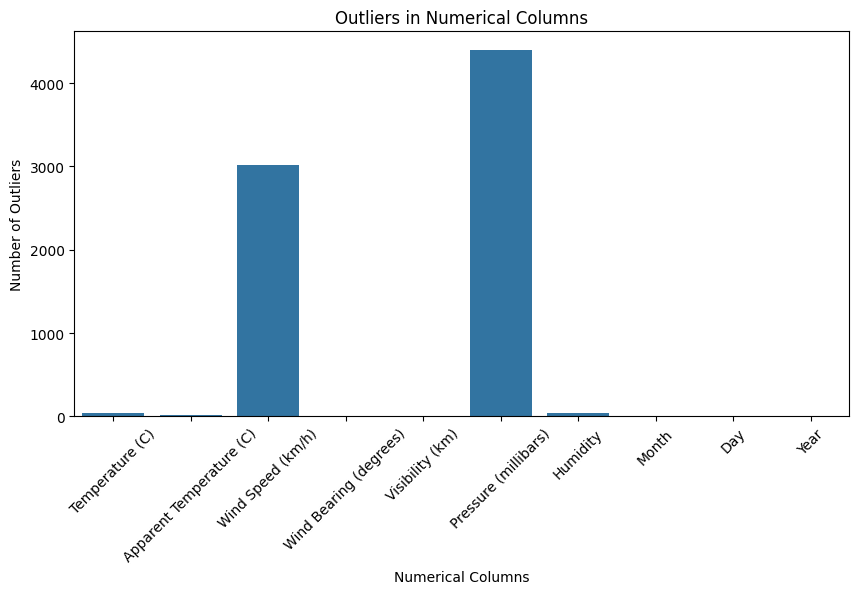

In [26]:
# Q4. Which numerical columns contain the highest number of outliers?


# Handle Missing Values
df['Precip Type'] = df['Precip Type'].fillna('No Precip')

# Remove Duplicate Rows
df = df.drop_duplicates()

# Detect Outliers Using IQR Method
outlier_counts = {}

for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = ((df[col] < Q1 - 1.5 * IQR) |
                (df[col] > Q3 + 1.5 * IQR)).sum()

    outlier_counts[col] = outliers
    print(col, "-> Outliers:", outliers)

# Visualize Outliers
plt.figure(figsize=(10,5))
sns.barplot(
    x=list(outlier_counts.keys()),
    y=list(outlier_counts.values())
)

plt.title("Outliers in Numerical Columns")
plt.xlabel("Numerical Columns")
plt.ylabel("Number of Outliers")
plt.xticks(rotation=45)
plt.show()


# Conclusion

The analysis shows that Pressure and Wind Speed contain the highest number of outliers. These outliers may represent real weather conditions, so they were not removed from the dataset.

Correlation: 0.3929386259083098


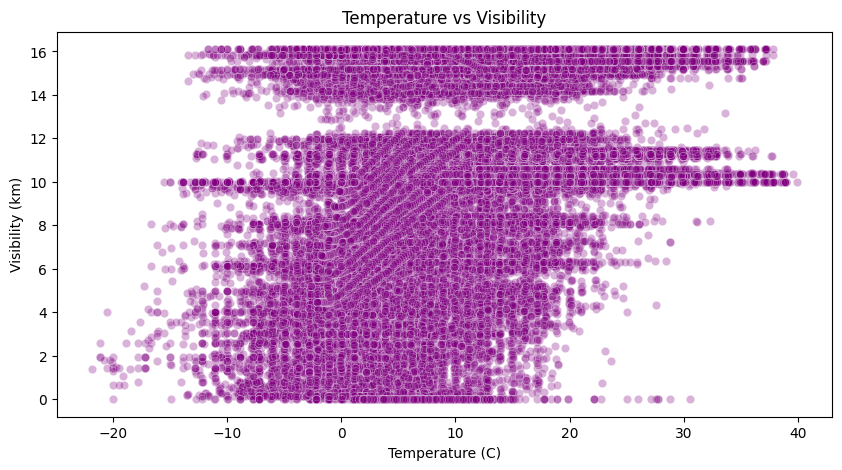

In [28]:
# Q5. How does visibility change with increasing temperature?


# Calculate Correlation
correlation = df['Temperature (C)'].corr(df['Visibility (km)'])

print("Correlation:", correlation)

# Scatter Plot
plt.figure(figsize=(10,5))
sns.scatterplot(
    x=df['Temperature (C)'],
    y=df['Visibility (km)'],
    color='purple',
    alpha=0.3
)

plt.title("Temperature vs Visibility")
plt.xlabel("Temperature (C)")
plt.ylabel("Visibility (km)")
plt.show()



# Conclusion

The analysis shows that Temperature and Visibility have a positive correlation. The scatter plot indicates that visibility varies at different temperatures. Therefore, higher temperatures are generally associated with better visibility in this dataset.